# **Step 2 — Data Cleaning & Standardisation: FAO Food Loss and Waste**

**Purpose:** turn the raw `World-food-waste.csv` into an analysis-ready table by applying, step by step, the issues found in *Step 1 — Data Exploration & Column Profiling*. Every cleaning rule below is tied to a finding from that notebook, and each step ends with a table showing exactly what changed in the data.

**Outputs (written to `cleaned_data/`):**

| File | Content |
|---|---|
| `world_food_loss_cleaned.csv` | the cleaned dataset (one row per source record) |
| `cleaning_change_log.csv` | one row per cleaning action: step, column, rule, rows affected |
| `cleaning_value_changes.csv` | every distinct *old value → new value* replacement with its row count |
| `data_quality_flags_summary.csv` | how many rows carry each review flag |

## Cleaning principles

1. **Fix what is provably wrong, flag what is only suspicious.** Whitespace, HTML tags, spelling variants and unit notation are fixed. Outliers, odd years and possible duplicates are *flagged* (`dq_flags`), never deleted — a 60 % loss for tomatoes is plausible, so removing it would bias the data.
2. **A null is not always a defect.** Each column's null policy depends on what a missing value *means* (see the table below).
3. **Keep provenance.** Where a column is transformed in a way that loses information (`loss_quantity`, `sample_size`, `loss_percentage_original`) the raw text is kept next to the clean value.
4. **Only exact duplicates are removed.**
5. **Everything is logged** so the cleaning can be audited and reproduced.

## Null-handling policy (decided per column from the data's meaning)

| Column | Raw nulls | What a null means | Decision |
|---|---:|---|---|
| `region` | 29,429 | record is national (or aggregate) — no sub-national area | **keep null**, add `is_subnational` |
| `activity` | 7,370 | activity not reported | fill with explicit `Not specified` |
| `food_supply_stage` | 3,391 | not reported; 3,342 of them are one APHLIS activity whose stage can be derived | **derive from sibling activities**, remaining → `Not specified` |
| `method_data_collection` | 36 | not reported (same meaning as the existing label *No Data Collection Specified*) | unify under `Not specified` |
| `treatment`, `cause_of_loss`, `notes` | 94–97 % | optional descriptors that simply do not apply to most records | **keep null** (filling would add noise) |
| `loss_quantity`, `sample_size` | 84 % / 94 % | optional measurements | **keep null**; clean the non-null values |
| `reference`, `url` | 73 / 9,342 | provenance gaps | **keep null**, flag rows that have neither |

## 1. Setup — libraries, configuration, and data location

In [1]:
import os
import re
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 220)

# --- configuration -----------------------------------------------------------
DATA_FILENAME = "World-food-waste.csv"
OUTPUT_DIR = Path("cleaned_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MIN_PLAUSIBLE_YEAR = 1965       # FAO FLW database documents records from 1965 (same bound as Step 1)
MAX_PLAUSIBLE_YEAR = 2026       # year of this analysis; later years are impossible
MISSING_TOKENS = {"NA", "N/A", "NULL", "NONE", "UNKNOWN", "MISSING", "-", "NAN"}
NOT_SPECIFIED = "Not specified"

# --- locate the source CSV (same lookup logic as the exploration notebook) ----
configured_path = os.getenv("FOOD_LOSS_DATA_PATH")
cwd = Path.cwd()
candidate_paths = ([Path(configured_path).expanduser()] if configured_path else []) + [
    cwd / DATA_FILENAME,
    cwd / "data-set" / DATA_FILENAME,
    cwd.parent / "data-set" / DATA_FILENAME,
    cwd / "data" / DATA_FILENAME,
    cwd.parent / "data" / DATA_FILENAME,
]
DATA_PATH = next((p.resolve() for p in candidate_paths if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not locate {DATA_FILENAME}. Set FOOD_LOSS_DATA_PATH or place the CSV "
        "next to this notebook."
    )
print("Source file :", DATA_PATH.name)
print("Output dir  :", OUTPUT_DIR)

Source file : World-food-waste.csv
Output dir  : cleaned_data


### Audit helpers

Three small helpers record what the cleaning does:

* `log_action` — one line per cleaning rule (step, column, rows affected);
* `log_value_changes` — every distinct *old → new* value replacement;
* `checkpoint` — shape and null-cell count (original columns) after each step, so the effect of every step is visible.

In [2]:
change_log = []          # one entry per cleaning rule applied
value_change_log = []    # one entry per distinct old -> new replacement
checkpoints = []         # shape / null count after every step


def _same(a, b):
    # Element-wise equality that treats two nulls as equal.
    return a.fillna("<NA>").astype("string").eq(b.fillna("<NA>").astype("string"))


def log_action(step, column, rule, rows_affected):
    change_log.append({"step": step, "column": column, "rule": rule,
                       "rows_affected": int(rows_affected)})


def log_value_changes(step, column, before, after):
    # Store each distinct old -> new replacement together with its row count.
    changed = ~_same(before, after)
    if not changed.any():
        return 0
    pairs = (pd.DataFrame({"old_value": before[changed].astype("string"),
                           "new_value": after[changed].astype("string")})
             .groupby(["old_value", "new_value"], dropna=False).size()
             .reset_index(name="rows"))
    pairs.insert(0, "column", column)
    pairs.insert(0, "step", step)
    value_change_log.extend(pairs.to_dict("records"))
    return int(changed.sum())


def checkpoint(step, frame):
    # Null cells are counted over the ORIGINAL columns only, so that new helper/derived
    # columns do not inflate the number. Text moved out of sample_size into
    # sample_size_description still counts as information.
    tracked = [c for c in frame.columns if c in set(raw.columns) | {"loss_quantity_raw"}]
    view = frame[tracked].copy()
    if "sample_size_description" in frame.columns:
        view["sample_size"] = view["sample_size"].astype("string").fillna(frame["sample_size_description"])
    nulls = int(view.isna().sum().sum())
    prev = checkpoints[-1] if checkpoints else None
    checkpoints.append({"step": step, "rows": len(frame), "columns": frame.shape[1],
                        "null_cells_original_columns": nulls})
    if prev:
        print(f"[checkpoint] {step}: rows {prev['rows']:,} -> {len(frame):,} | "
              f"columns {prev['columns']} -> {frame.shape[1]} | "
              f"null cells (original columns) {prev['null_cells_original_columns']:,} -> {nulls:,}")
    else:
        print(f"[checkpoint] {step}: rows {len(frame):,} | columns {frame.shape[1]} | "
              f"null cells (original columns) {nulls:,}")


def most_frequent_label(values):
    # Most common label; ties are resolved alphabetically so the result is deterministic.
    counts = values.value_counts().sort_index()
    return counts.sort_values(ascending=False, kind="stable").index[0]


def consolidate_variants(series):
    # Merge labels that differ only by case / spacing into the most frequent spelling.
    key = series.str.casefold().str.replace(r"\s+", " ", regex=True).str.strip()
    canonical = series.groupby(key).transform(most_frequent_label)
    return canonical.where(series.notna())

## 2. Load the raw data

All columns are first read as **text** (`dtype=str`) and with pandas' automatic null-detection switched off except for truly empty cells. That way nothing is silently coerced on load — types are converted deliberately, column by column, in the steps below. A `source_row_id` is added so every cleaned row can be traced back to its line in the raw CSV.

In [3]:
raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False, na_values=[""], low_memory=False)

df = raw.copy()
for col in df.columns:
    df[col] = df[col].astype("string")
df.insert(0, "source_row_id", np.arange(len(df)))          # 0-based row in the raw CSV

print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns")
checkpoint("0. raw load", df)

raw_null_pct = raw.isna().mean().mul(100).round(2).rename("raw_missing_pct")
display(pd.concat([raw.isna().sum().rename("raw_missing"), raw_null_pct], axis=1)
        .sort_values("raw_missing", ascending=False))
display(df.head(3).T.rename(columns=lambda c: f"row {c}"))

Loaded 31,465 rows x 18 columns
[checkpoint] 0. raw load: rows 31,465 | columns 19 | null cells (original columns) 195,635


,raw_missing,raw_missing_pct
cause_of_loss,30367,96.51
notes,29931,95.12
treatment,29678,94.32
sample_size,29603,94.08
region,29429,93.53
loss_quantity,26415,83.95
url,9342,29.69
activity,7370,23.42
food_supply_stage,3391,10.78
reference,73,0.23


,row 0,row 1,row 2
source_row_id,0,1,2
m49_code,1,1,1
country,World,World,World
region,<NA>,<NA>,<NA>
cpc_code,0111,0112,0112
commodity,Wheat,Maize (corn),Maize (corn)
year,2022,2022,2022
loss_percentage,1,0.5,2
loss_percentage_original,1%,0.5%,2%
loss_quantity,<NA>,<NA>,<NA>


## 3. Step 1 — Standardise text and hidden missing values

**Finding (Step 1 exploration):** text columns contain leading/trailing spaces, repeated internal spaces (`Southern  Nations,  Nationalities`), typographic ligatures (`Modiﬁed` with the single character *ﬁ*), and a few placeholder tokens (`-` in `sample_size`) that are really missing values.

**Rule applied to every text column:**
1. Unicode NFKC normalisation (expands ligatures, unifies look-alike characters).
2. Trim and collapse repeated whitespace.
3. Empty strings → null.
4. Placeholder tokens (`NA`, `N/A`, `NULL`, `NONE`, `UNKNOWN`, `MISSING`, `-`, `NAN`, whole-cell match only) → null.

In [4]:
STEP = "1. text normalisation"
text_columns = [c for c in df.columns if c != "source_row_id"]
rows = []

for col in text_columns:
    original = df[col]
    unicode_fixed = original.map(lambda v: unicodedata.normalize("NFKC", v) if isinstance(v, str) else v).astype("string")
    spaced = unicode_fixed.str.replace(r"\s+", " ", regex=True).str.strip()

    blank = spaced.notna() & spaced.eq("")
    token = spaced.notna() & ~blank & spaced.str.upper().isin(MISSING_TOKENS)
    cleaned = spaced.mask(blank | token, pd.NA)

    rows.append({
        "column": col,
        "unicode_changed": int((~_same(original, unicode_fixed)).sum()),
        "whitespace_fixed": int((~_same(unicode_fixed, spaced)).sum()),
        "blank_to_null": int(blank.sum()),
        "token_to_null": int(token.sum()),
    })
    log_value_changes(STEP, col, original, cleaned)
    df[col] = cleaned

step1_report = pd.DataFrame(rows).set_index("column")
step1_report["total_cells_changed"] = step1_report.sum(axis=1)
print("Cells changed per column (only columns that changed):")
display(step1_report[step1_report["total_cells_changed"] > 0].sort_values("total_cells_changed", ascending=False))

for col, r in step1_report.iterrows():
    if r["total_cells_changed"]:
        log_action(STEP, col, "NFKC + trim/collapse whitespace + blank/placeholder -> null",
                   r["total_cells_changed"])

checkpoint(STEP, df)

Cells changed per column (only columns that changed):


,unicode_changed,whitespace_fixed,blank_to_null,token_to_null,total_cells_changed
column,,,,,
notes,0,262,0,0,262
reference,34,113,0,0,147
cause_of_loss,1,128,0,0,129
sample_size,0,83,0,6,89
region,0,84,0,0,84
treatment,12,53,0,0,65
loss_quantity,0,8,0,0,8
loss_percentage_original,0,6,0,0,6


[checkpoint] 1. text normalisation: rows 31,465 -> 31,465 | columns 19 -> 19 | null cells (original columns) 195,635 -> 195,641


## 4. Step 2 — Remove exact duplicate rows

**Finding:** 180 rows are repeated copies of another row in *all* columns. These carry no extra information and would double-count losses, so they are removed (first occurrence kept).

Rows that merely share the same key attributes but have *different* values are **not** removed — they are flagged later (Step 14) because they may be separate measurements.

In [5]:
STEP = "2. exact duplicates"
data_columns = [c for c in df.columns if c != "source_row_id"]

raw_duplicates = int(raw.duplicated().sum())
dup_mask = df.duplicated(subset=data_columns, keep="first")
print(f"Exact duplicates in the raw file  : {raw_duplicates}")
print(f"Exact duplicates after normalising: {int(dup_mask.sum())}")

# show a few duplicated records (all copies) so the removal is easy to verify
dup_all_copies = df.duplicated(subset=data_columns, keep=False)
print(f"\nRows involved in duplication (all copies): {int(dup_all_copies.sum())}")
print("Sample - identical records sit side by side (compare source_row_id):")
display(df[dup_all_copies]
        .sort_values(["country", "commodity", "year", "source_row_id"])
        [["source_row_id", "country", "commodity", "year", "loss_percentage", "activity", "reference"]]
        .head(6))

df = df.loc[~dup_mask].reset_index(drop=True)
log_action(STEP, "(all)", "dropped exact duplicate rows, kept first occurrence", dup_mask.sum())
checkpoint(STEP, df)

Exact duplicates in the raw file  : 180
Exact duplicates after normalising: 180

Rows involved in duplication (all copies): 339
Sample - identical records sit side by side (compare source_row_id):


,source_row_id,country,commodity,year,loss_percentage,activity,reference
17381,17381,Armenia,Wheat,2013,5,"Handling, Storage","FAO, (2013), Food Losses And Waste In Europe And Central Asia"
17382,17382,Armenia,Wheat,2013,5,"Handling, Storage","FAO, (2013), Food Losses And Waste In Europe And Central Asia"
18013,18013,Australia and New Zealand,Mixed grain,2014,38,<NA>,"Radojko Lukic; Dragana Vojteski Kljenak; Dragica Jovancevic, (2014..."
18014,18014,Australia and New Zealand,Mixed grain,2014,38,<NA>,"Radojko Lukic; Dragana Vojteski Kljenak; Dragica Jovancevic, (2014..."
16120,16120,Bangladesh,Bananas,2010,7.7,<NA>,"Md Kamrul Hassan; Bishan Lal Das Chowdhury; Nasrin Akhter, (2010),..."
16121,16121,Bangladesh,Bananas,2010,5.1,<NA>,"Md Kamrul Hassan; Bishan Lal Das Chowdhury; Nasrin Akhter, (2010),..."


[checkpoint] 2. exact duplicates: rows 31,465 -> 31,285 | columns 19 -> 19 | null cells (original columns) 195,641 -> 194,413


## 5. Step 3 — `m49_code` and `country`

**Findings (Step 1):**
* `m49_code` has no nulls, but M49 codes are *identifiers*, not quantities — they should be 3-character strings (`004`, not `4`) so they join to the UN M49 reference.
* Six names differ from the current official UN M49 names: `Palestine`, `Netherlands`, `Turkey`, `The former Yugoslav Republic of Macedonia`, `United Kingdom`, and `China,Taiwan` — the last one is the same entity (code 158) as the already-correct `Taiwan, Province of China`, so Taiwan appears under two names.
* The `country` column also contains **geographic aggregates** (World, Africa, Western Africa, Europe, …). They are valid FAO modelled estimates, but if they are summed together with countries every loss is double-counted.

**Decisions:**
1. Convert `m49_code` to a zero-padded 3-character string.
2. Rename the six aliases to the official UN names — each rename is only applied when the code in the data **agrees** with the expected official code, so a name is never "fixed" onto the wrong entity.
3. Guarantee a strict one-code ↔ one-name relationship.
4. Keep aggregate rows but label them (`geo_level`, `is_aggregate`) so analysis can include or exclude them explicitly.

In [6]:
STEP = "3. m49_code + country"
before_country = df["country"].copy()

# 1) m49_code -> zero-padded 3-character identifier
m49_numeric = pd.to_numeric(df["m49_code"], errors="raise")
assert m49_numeric.notna().all() and (m49_numeric % 1 == 0).all() and m49_numeric.between(1, 999).all()
df["m49_code"] = m49_numeric.astype(int).astype(str).str.zfill(3).astype("string")
log_action(STEP, "m49_code", "text -> zero-padded 3-character code", len(df))

# 2) alias -> official UN M49 name; the code in the data must match the expected official code
COUNTRY_NAME_MAP = {
    "China,Taiwan":                              ("Taiwan, Province of China", "158"),
    "Palestine":                                 ("State of Palestine", "275"),
    "Netherlands":                               ("Netherlands (Kingdom of the)", "528"),
    "Turkey":                                    ("Türkiye", "792"),
    "The former Yugoslav Republic of Macedonia": ("North Macedonia", "807"),
    "United Kingdom":                            ("United Kingdom of Great Britain and Northern Ireland", "826"),
}

mapping_report = (df[df["country"].isin(COUNTRY_NAME_MAP)]
                  .groupby(["country", "m49_code"]).size().reset_index(name="rows"))
mapping_report["official_name"] = mapping_report["country"].map(lambda n: COUNTRY_NAME_MAP[n][0])
mapping_report["expected_code"] = mapping_report["country"].map(lambda n: COUNTRY_NAME_MAP[n][1])
mapping_report["code_agrees"] = mapping_report["m49_code"].eq(mapping_report["expected_code"])
print("Alias -> official name (applied only where the code agrees):")
display(mapping_report)
assert mapping_report["code_agrees"].all(), "A name/code pair disagrees - review before renaming"

df["country"] = df["country"].replace({k: v[0] for k, v in COUNTRY_NAME_MAP.items()})
n_renamed = log_value_changes(STEP, "country", before_country, df["country"])
log_action(STEP, "country", "aliases renamed to official UN M49 names", n_renamed)

# 3) one code <-> one name
names_per_code = df.groupby("m49_code")["country"].nunique()
codes_per_name = df.groupby("country")["m49_code"].nunique()
print(f"\nCodes with more than one name : {(names_per_code > 1).sum()}")
print(f"Names with more than one code : {(codes_per_name > 1).sum()}")
assert (names_per_code == 1).all() and (codes_per_name == 1).all()
print(f"Distinct country/area names: {df['country'].nunique()}  (was {before_country.nunique()})")

Alias -> official name (applied only where the code agrees):


,country,m49_code,rows,official_name,expected_code,code_agrees
0,"China,Taiwan",158,1,"Taiwan, Province of China",158,True
1,Netherlands,528,67,Netherlands (Kingdom of the),528,True
2,Palestine,275,51,State of Palestine,275,True
3,The former Yugoslav Republic of Macedonia,807,21,North Macedonia,807,True
4,Turkey,792,13,Türkiye,792,True
5,United Kingdom,826,48,United Kingdom of Great Britain and Northern Ireland,826,True



Codes with more than one name : 0
Names with more than one code : 0
Distinct country/area names: 157  (was 159)


### Label geographic aggregates

M49 assigns fixed codes to the world, regions, sub-regions and intermediate regions. The dictionary below lists every aggregate that appears in this dataset. The cell **verifies that the name in the data matches the official name for that code** before labelling, so a wrongly coded row would fail loudly instead of being mislabelled.

In [7]:
# Official UN M49 geographic aggregates present in the data: code -> (official name, level)
M49_AGGREGATES = {
    "001": ("World", "World"),
    "002": ("Africa", "Region"),
    "142": ("Asia", "Region"),
    "150": ("Europe", "Region"),
    "015": ("Northern Africa", "Sub-region"),
    "202": ("Sub-Saharan Africa", "Sub-region"),
    "021": ("Northern America", "Sub-region"),
    "419": ("Latin America and the Caribbean", "Sub-region"),
    "143": ("Central Asia", "Sub-region"),
    "145": ("Western Asia", "Sub-region"),
    "034": ("Southern Asia", "Sub-region"),
    "035": ("South-Eastern Asia", "Sub-region"),
    "053": ("Australia and New Zealand", "Sub-region"),
    "011": ("Western Africa", "Intermediate region"),
}

agg_in_data = df[df["m49_code"].isin(M49_AGGREGATES)].groupby(["m49_code", "country"]).size().reset_index(name="rows")
agg_in_data["official_name"] = agg_in_data["m49_code"].map(lambda c: M49_AGGREGATES[c][0])
assert (agg_in_data["country"] == agg_in_data["official_name"]).all(), "aggregate code/name mismatch"

df["geo_level"] = df["m49_code"].map(lambda c: M49_AGGREGATES[c][1] if c in M49_AGGREGATES else "Country/Area").astype("string")
df["is_aggregate"] = df["geo_level"].ne("Country/Area").astype(bool)
log_action(STEP, "geo_level, is_aggregate", "new columns: label M49 aggregates vs countries/areas", df["is_aggregate"].sum())

print("Aggregates found (name verified against code):")
display(agg_in_data.assign(level=agg_in_data["m49_code"].map(lambda c: M49_AGGREGATES[c][1])).drop(columns="official_name"))
display(df["geo_level"].value_counts().rename_axis("geo_level").reset_index(name="rows"))
print(f"Aggregate rows: {df['is_aggregate'].sum():,} of {len(df):,} ({df['is_aggregate'].mean():.1%}). "
      "Filter `~is_aggregate` before summing across countries.")
checkpoint(STEP, df)

Aggregates found (name verified against code):


,m49_code,country,rows,level
0,001,World,29,World
1,002,Africa,4,Region
2,011,Western Africa,4,Intermediate region
3,015,Northern Africa,5,Sub-region
4,021,Northern America,5,Sub-region
5,034,Southern Asia,5,Sub-region
6,035,South-Eastern Asia,6,Sub-region
7,053,Australia and New Zealand,2,Sub-region
8,142,Asia,1,Region
9,143,Central Asia,5,Sub-region


,geo_level,rows
0,Country/Area,31178
1,Sub-region,55
2,World,29
3,Region,19
4,Intermediate region,4


Aggregate rows: 107 of 31,285 (0.3%). Filter `~is_aggregate` before summing across countries.
[checkpoint] 3. m49_code + country: rows 31,285 -> 31,285 | columns 19 -> 21 | null cells (original columns) 194,413 -> 194,413


## 6. Step 4 — `region`

**Findings (Step 1):** `region` is **free-text sub-national detail** (provinces, districts, markets, agro-ecological zones — 378 distinct raw values) provided only when a study covered part of a country. Therefore:

* **~93 % nulls are legitimate** — they mean *national* coverage. They are **not imputed**; instead `is_subnational` states the meaning explicitly.
* `National average` (a handful of rows) is not a sub-national area — it is a national-scope marker, so it becomes null.
* Real inconsistencies exist: case variants (`Xiasha Town` / `Xiasha town`), a stray `?` prefix, `Region - 2` vs `Region 2`, spaces before commas, and unambiguous typos (`Banglore`, `Anadhra Pradesh`, `Madhya Pardesh`, `Apac Districy`, `Bani Suef`, `Slavador`, …).

Only unambiguous typos are corrected; ambiguous names are left exactly as the source gave them.

In [8]:
STEP = "4. region"
before_region = df["region"].copy()

REGION_TYPO_FIXES = {
    r"\bBanglore\b": "Bangalore",     r"\bAnadhra\b": "Andhra",       r"\bPardesh\b": "Pradesh",
    r"\bDistricy\b": "District",      r"\bTiajin\b": "Tianjin",       r"\bSlavador\b": "Salvador",
    r"\bans\b": "and",                r"\bBani Suef\b": "Beni Suef",  r"\bDakha\b": "Dhaka",
    r"\bShalyan\b": "Salyan",         r"\bOromiya\b": "Oromia",
    r"\bMoisttransitional\b": "Moist Transitional", r"\bMoistmid\b": "Moist Mid",
}

region = df["region"]
region = region.str.replace(r"^\?\s*", "", regex=True)                  # stray "? " prefix
region = region.str.replace(r"\s+([,;.])", r"\1", regex=True)            # space before punctuation
region = region.str.replace(r"^Region\s*-\s*(\d+)$", r"Region \1", regex=True)
for pattern, fix in REGION_TYPO_FIXES.items():
    region = region.str.replace(pattern, fix, regex=True)
region = region.mask(region.str.casefold().eq("national average"), pd.NA)  # national scope, not an area
region = consolidate_variants(region)                                    # case variants -> most frequent form

n_changed = log_value_changes(STEP, "region", before_region, region)
log_action(STEP, "region", "typo fixes, spacing/prefix cleanup, 'National average' -> null, case variants merged", n_changed)
df["region"] = region.astype("string")

df["is_subnational"] = df["region"].notna()
log_action(STEP, "is_subnational", "new column: region present = sub-national study area", df["is_subnational"].sum())

print(f"Distinct region labels: {before_region.nunique()} -> {df['region'].nunique()}")
print(f"Rows changed: {n_changed}")
display(pd.DataFrame({"records": df["is_subnational"].value_counts()})
        .rename(index={True: "sub-national (region given)", False: "national / aggregate (region null)"}))

changes = pd.DataFrame(value_change_log)
display(changes[(changes["step"] == STEP) & (changes["column"] == "region")]
        .sort_values("rows", ascending=False).head(15).reset_index(drop=True))
checkpoint(STEP, df)

Distinct region labels: 374 -> 363


Rows changed: 154


,records
is_subnational,
national / aggregate (region null),29262
sub-national (region given),2023


,step,column,old_value,new_value,rows
0,4. region,region,"Bawku, Wa Tamale, Yendi , Techiman, and Kintampo","Bawku, Wa Tamale, Yendi, Techiman, and Kintampo",36
1,4. region,region,"State of Bahia, Slavador","State of Bahia, Salvador",24
2,4. region,region,National average,NaN,11
3,4. region,region,Oromiya,Oromia,8
4,4. region,region,Moistmid Altitude Zone,Moist Mid Altitude Zone,8
5,4. region,region,Moisttransitional Zone,Moist Transitional Zone,8
6,4. region,region,Banglore,Bangalore,7
7,4. region,region,Region - 5,Region 5,7
8,4. region,region,Region - 3,Region 3,7
9,4. region,region,Region - 2,Region 2,7


[checkpoint] 4. region: rows 31,285 -> 31,285 | columns 21 -> 22 | null cells (original columns) 194,413 -> 194,424


## 7. Step 5 — `cpc_code` and `commodity`

**Findings (Step 1):**
* `cpc_code` is an **identifier with leading zeros** (`0111`, `01199.90`) and must stay text.
* Two codes carry a letter suffix (`21116i`, `2351f`). These are FAO-extended CPC codes (indigenous goat meat; raw centrifugal sugar), **not typos**, so they are kept and flagged for awareness.
* 17 CPC codes are attached to more than one commodity *label*. The cause is purely textual: HTML tags (`<i>Capsicum</i>`), a truncated suffix (`n.e.` vs `n.e.c.`), case (`Rice, Milled` / `Rice, milled`), word variants and one misspelling (`Raspeberries`).
* The reverse never happens — no commodity label maps to two codes — so the **CPC code is a reliable key** for the label.

**Rule:** strip HTML tags → repair the truncated `n.e.` suffix → give every CPC code a single canonical label = its most frequent label (ties alphabetical). The full label mapping is displayed for review.

In [9]:
STEP = "5. cpc_code + commodity"
before_commodity = df["commodity"].copy()

# --- cpc_code: syntax audit (identifier stays text, nothing is altered) --------
cpc = df["cpc_code"]
standard = cpc.str.fullmatch(r"\d{4,5}(?:\.\d{2})?")
fao_extended = cpc.str.fullmatch(r"\d{4,5}[a-z]")
print("cpc_code syntax audit:")
display(pd.DataFrame({
    "standard CPC (4-5 digits, optional .NN)": [int(standard.sum())],
    "FAO-extended (letter suffix)":            [int(fao_extended.sum())],
    "unrecognised":                            [int((~standard & ~fao_extended).sum())],
    "nulls":                                   [int(cpc.isna().sum())],
}))
print("FAO-extended codes kept as-is:", sorted(cpc[fao_extended].unique()))
assert (~standard & ~fao_extended).sum() == 0

# --- commodity: text clean-up --------------------------------------------------
commodity = df["commodity"]
commodity = commodity.str.replace(r"</?i>", "", regex=True)                       # HTML italics
commodity = commodity.str.replace(r"\bn\.e\.(?=,|$)", "n.e.c.", regex=True)       # truncated "n.e."
df["commodity"] = commodity.astype("string")

# --- one canonical label per CPC code (most frequent label) --------------------
labels_per_code = df.groupby("cpc_code")["commodity"].nunique()
multi = labels_per_code[labels_per_code > 1].index
canonical = df.groupby("cpc_code")["commodity"].agg(most_frequent_label)
df["commodity"] = df["cpc_code"].map(canonical).astype("string")

review = (pd.DataFrame({"cpc_code": df["cpc_code"], "before": before_commodity, "after": df["commodity"]})
          .query("before != after").groupby(["cpc_code", "before", "after"]).size().reset_index(name="rows"))
print(f"\nCPC codes that had >1 commodity label (after text clean-up): {len(multi)}")
print("Label mapping applied (review - 'after' is the most frequent label for that code):")
display(review.sort_values(["cpc_code", "rows"], ascending=[True, False]).reset_index(drop=True))

n_changed = log_value_changes(STEP, "commodity", before_commodity, df["commodity"])
log_action(STEP, "commodity", "strip HTML tags, n.e.->n.e.c., one canonical label per cpc_code", n_changed)

# --- verify the code <-> label relationship is now 1:1 --------------------------
assert (df.groupby("cpc_code")["commodity"].nunique() == 1).all()
assert (df.groupby("commodity")["cpc_code"].nunique() == 1).all()
print(f"\nDistinct commodity labels: {before_commodity.nunique()} -> {df['commodity'].nunique()}  | "
      f"distinct CPC codes: {df['cpc_code'].nunique()}  (1 code = 1 label)")
checkpoint(STEP, df)

cpc_code syntax audit:


,"standard CPC (4-5 digits, optional .NN)",FAO-extended (letter suffix),unrecognised,nulls
0,31278,7,0,0


FAO-extended codes kept as-is: ['21116i', '2351f']

CPC codes that had >1 commodity label (after text clean-up): 11
Label mapping applied (review - 'after' is the most frequent label for that code):


,cpc_code,before,after,rows
0,01199.90,Other cereals n.e.,Other cereals n.e.c.,24
1,01199.90,Cereals n.e.c.,Other cereals n.e.c.,6
2,01231,"Chillies and peppers, green (<i>Capsicum</i> spp. and <i>Pimenta</...","Chillies and peppers, green (Capsicum spp. and Pimenta spp.)",36
3,01290.90,"Other vegetables, fresh n.e.","Other vegetables, fresh n.e.c.",10
4,01313,Plantains and cooking bananas,Plantains and others,9
5,01316,"Mangoes, guavas, mangosteens","Mangoes, guavas and mangosteens",12
6,01319,"Other tropical and subtropical fruits, n.e.","Other tropical and subtropical fruits, n.e.c.",1
7,01329,"Other citrus fruit, n.e.","Other citrus fruit, n.e.c.",2
8,01353.01,Raspeberries,Raspberries,6
9,01355.02,Cranberries and other fruits of the genus Vaccinium,Cranberries,8



Distinct commodity labels: 213 -> 196  | distinct CPC codes: 196  (1 code = 1 label)
[checkpoint] 5. cpc_code + commodity: rows 31,285 -> 31,285 | columns 22 -> 22 | null cells (original columns) 194,424 -> 194,424


## 8. Step 6 — `year`

**Findings (Step 1):** no nulls; the values are 4-digit years from 2000 to 2026. Year is a *measure of time*, so it is converted to integer. A year is flagged for review (not changed) when:

* it is `2025` or later — extremely few studies exist for those years;
* it is **later than the publication year printed in the `reference`**, e.g. 2026 data cited from a 2021 study. This is only a weak check: modelled estimates may legitimately project forward, so it is a review flag, not an error.

In [10]:
STEP = "6. year"
year_numeric = pd.to_numeric(df["year"], errors="raise")
assert year_numeric.notna().all() and (year_numeric % 1 == 0).all()
df["year"] = year_numeric.astype("Int64")
log_action(STEP, "year", "text -> Int64", len(df))

print(f"Year range: {df['year'].min()} - {df['year'].max()} "
      f"(accepted window {MIN_PLAUSIBLE_YEAR}-{MAX_PLAUSIBLE_YEAR})")
assert df["year"].between(MIN_PLAUSIBLE_YEAR, MAX_PLAUSIBLE_YEAR).all()

reference_year = pd.to_numeric(df["reference"].str.extract(r"\((\d{4})\)")[0], errors="coerce")
df["_reference_year"] = reference_year.astype("Int64")        # helper used by the flag step, dropped later
after_ref = (df["year"] > df["_reference_year"]).fillna(False)

display(df["year"].value_counts().sort_index().rename_axis("year").reset_index(name="rows").T)
print(f"\nRows with year >= 2025                         : {int((df['year'] >= 2025).sum())}")
print(f"Rows where year is after the reference's year  : {int(after_ref.sum())} "
      f"(reference year could be read for {int(reference_year.notna().sum()):,} rows)")
display(df.loc[after_ref & (df['year'] - df['_reference_year'] >= 3),
               ["country", "commodity", "year", "_reference_year", "method_data_collection"]]
        .drop_duplicates().rename(columns={"_reference_year": "reference_year"}).head(10))
checkpoint(STEP, df)

Year range: 2000 - 2026 (accepted window 1965-2026)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26
year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
rows,1266,1418,1342,1289,1222,1304,1703,1293,1392,1713,1506,1380,1261,1492,1896,1615,1634,1466,1432,1179,953,1053,231,80,155,5,5



Rows with year >= 2025                         : 10
Rows where year is after the reference's year  : 131 (reference year could be read for 26,947 rows)


,country,commodity,year,reference_year,method_data_collection
2119,China,Rice,2013,2010,Literature Review
4372,Ethiopia,Wheat,2010,1988,Survey
4373,Ethiopia,Maize (corn),2010,1988,Survey
8022,Ghana,Maize (corn),2001,1998,Controlled Experiment
9858,India,Rice,2013,2010,Literature Review
12416,Kenya,Maize (corn),2013,2010,Literature Review
14256,Malawi,Maize (corn),2013,2010,Literature Review
14257,Malawi,Sorghum,2013,2010,Literature Review
16058,Bangladesh,Cauliflowers and broccoli,2010,2006,Survey
17834,Nepal,Maize (corn),2013,2010,Literature Review


[checkpoint] 6. year: rows 31,285 -> 31,285 | columns 22 -> 23 | null cells (original columns) 194,424 -> 194,424


## 9. Step 7 — `loss_percentage` and `loss_percentage_original`

**Findings (Step 1):** `loss_percentage` is complete and numeric (0–65), `loss_percentage_original` is the text exactly as the source study reported it (`"1%"`, `"0.5"`, `"5-10%"`, `"1.5 -2 %"`).

**Checks and decisions**
1. Confirm the numeric column lies in the valid 0–100 range (no negatives, no values > 100). Values between 0 and 1 are checked against the original text: if the source wrote `0.5%` the number really is 0.5 %, not a 0.005 fraction.
2. Re-derive the number from the original text and compare. Where the original is a **range** (`40-80%`), the numeric value should be the **midpoint** — verify that this is how the source built it. The parser must also read leading-dot decimals such as `.5-1` (= 0.5–1), otherwise it would read them as 5 and 1.
3. Keep `loss_percentage_original` untouched (it is the provenance of the number) and add `loss_pct_is_range` so analysts know which values are midpoints of a range.
4. A **global** outlier fence would wrongly flag all fruit/vegetable records (their losses are naturally higher than cereals), so outliers are judged **within commodity group** in Step 14 and only flagged.

In [11]:
STEP = "7. loss_percentage"
loss = pd.to_numeric(df["loss_percentage"], errors="raise")
df["loss_percentage"] = loss.astype("float64")
log_action(STEP, "loss_percentage", "text -> float64", len(df))

# 1) range checks
range_checks = pd.Series({
    "nulls": int(loss.isna().sum()),
    "negative": int((loss < 0).sum()),
    "greater than 100": int((loss > 100).sum()),
    "exactly 0": int((loss == 0).sum()),
    "between 0 and 1 (possible fractions)": int(((loss > 0) & (loss < 1)).sum()),
}, name="rows")
display(range_checks.to_frame())
assert range_checks[["nulls", "negative", "greater than 100"]].sum() == 0

# 2) re-derive from the original text
NUMBER = re.compile(r"\d+(?:\.\d+)?|\.\d+")      # also reads leading-dot decimals such as ".5-1"

def parse_original(text):
    # Return (value, kind): single number, midpoint of a range, or unparseable.
    if pd.isna(text):
        return np.nan, "missing"
    nums = [float(x) for x in NUMBER.findall(text)]
    if len(nums) == 1:
        return nums[0], "single"
    if len(nums) == 2:
        return float(np.mean(nums)), "range"
    return np.nan, "unparseable"

parsed = df["loss_percentage_original"].map(parse_original)
parsed_value = parsed.map(lambda t: t[0]).astype("float64")
original_kind = parsed.map(lambda t: t[1])
agrees = np.isclose(df["loss_percentage"], parsed_value, rtol=0, atol=0.01)

audit = (pd.DataFrame({"kind": original_kind, "agrees": agrees})
         .groupby("kind")["agrees"].agg(rows="size", agree="sum").assign(disagree=lambda d: d["rows"] - d["agree"]))
print("Numeric value vs value re-derived from loss_percentage_original:")
display(audit)
assert audit.loc[audit.index != "missing", "disagree"].sum() == 0, "numeric value disagrees with its original text"

df["loss_pct_is_range"] = original_kind.eq("range")
log_action(STEP, "loss_pct_is_range", "new column: original text was a range, value = midpoint", df["loss_pct_is_range"].sum())

print("\nExamples of range originals and the midpoint stored in loss_percentage:")
display(df.loc[df["loss_pct_is_range"], ["country", "commodity", "loss_percentage_original", "loss_percentage"]].drop_duplicates().sample(8, random_state=1))

display(df["loss_percentage"].describe(percentiles=[.05, .25, .5, .75, .95, .99]).to_frame("loss_percentage").T)
checkpoint(STEP, df)

,rows
nulls,0
negative,0
greater than 100,0
exactly 0,60
between 0 and 1 (possible fractions),3186


Numeric value vs value re-derived from loss_percentage_original:


,rows,agree,disagree
kind,,,
range,890,890,0
single,30395,30395,0



Examples of range originals and the midpoint stored in loss_percentage:


,country,commodity,loss_percentage_original,loss_percentage
3131,Benin,"Onions and shallots, green",6.0-50,28.00
18493,Nigeria,Tomatoes,10-15%,12.50
6116,Finland,Carrots and turnips,10-20,15.00
10608,Indonesia,"Onions and shallots, green",1-2%,1.50
7682,Ghana,Oranges,0-2,1.00
974,Canada,"Meat of cattle, fresh or chilled",3 - 4%,3.50
7700,Ghana,"Cassava, fresh",0 - 0.9,0.45
10046,India,Okra,2 - 7%,4.50


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
loss_percentage,31285.0,4.661938,6.36073,0.0,0.41,1.48148,2.65,4.55,16.408,35.0,65.0


[checkpoint] 7. loss_percentage: rows 31,285 -> 31,285 | columns 23 -> 24 | null cells (original columns) 194,424 -> 194,424


## 10. Step 8 — `loss_quantity` (mixed units → tonnes)

**Findings (Step 1):** `loss_quantity` is text with **at least 6 different unit systems mixed in one column**: bare numbers (`6700`), `kg`, `kgs`, `quintals`, `tons`/`tonnes`, `thousand tons`, `million tons`, thousands separators (`5,799.33 kg`, `36 275`), ranges (`541-2893 KG`), and entries that are **not a quantity at all** but a rate or a count (`52kg/MT`, `3 ton/ha`, `11 kg/capita`, `3.99 million head`, `4 kgs per acre`). Summing or comparing the column as it stands would be meaningless.

**Decisions**
* Create `loss_quantity_tonnes` (float) using exact conversions: 1 kg = 0.001 t, 1 quintal = 100 kg = 0.1 t, *thousand* ×1,000, *million* ×1,000,000.
* **Bare numbers with no unit** (≈ 4,300 rows) are assumed to be **tonnes** — the unit used by the FAO FLW database — and are labelled `assumed_tonnes_no_unit` so the assumption stays visible and can be revisited.
* **Ranges** → midpoint (the same convention the source used for percentages), flagged by `loss_quantity_is_range`.
* **Rates and counts** (per tonne, hectare, acre, capita, household, head, %) cannot be turned into a total quantity → left null in `loss_quantity_tonnes`, labelled `not_convertible`.
* The original text is preserved as `loss_quantity_raw`.

In [12]:
STEP = "8. loss_quantity"
NUM = re.compile(r"\d+(?:\.\d+)?|\.\d+")
RATE_UNIT = re.compile(r"/|\bper\b|\bha\b|capita|household|head|farm|%|acre|kga")

def parse_quantity(raw_value):
    # Return (tonnes, basis, is_range) for one loss_quantity string.
    if pd.isna(raw_value):
        return np.nan, pd.NA, False
    s = str(raw_value).lower()
    if re.fullmatch(r"\d+(?:\.\d*)?(?:e[-+]?\d+)?|\.\d+", s):             # plain number, incl. 1e+05
        return float(s), "assumed_tonnes_no_unit", False
    s = re.sub(r"(?<=\d),(?=\d{3}(?:\D|$))", "", s)                  # 5,799.33 -> 5799.33
    s = re.sub(r"(?<=\d) (?=\d{3}(?:\D|$))", "", s)                  # 36 275  -> 36275
    s = re.sub(r"\(\s*000\s*([a-z]*)\s*\)", r" thousand \1 ", s)     # (000 ton) -> thousand ton
    s = re.sub(r"/\s*(year|yr)\b|\bper\s+year\b|\byear\b", " ", s)   # "per year" does not change the unit

    nums = [float(x) for x in NUM.findall(s)]
    unit = re.sub(r"\s+", " ", re.sub(r"[-\u2013\u2014]", " ", NUM.sub(" ", s))).strip()
    is_range = len(nums) == 2 and re.search(r"\d\s*[-\u2013\u2014]\s*\d", s) is not None

    if not nums or len(nums) > 2 or (len(nums) == 2 and not is_range):
        return np.nan, "not_convertible", False
    value = float(np.mean(nums))

    if unit == "":
        return value, "assumed_tonnes_no_unit", is_range
    if RATE_UNIT.search(unit):                                        # rate or count, not a total
        return np.nan, "not_convertible", is_range

    multiplier = 1e6 if re.search(r"\b(million|milion|m)\b", unit) else 1e3 if "thousand" in unit else 1.0
    base = re.sub(r"\b(million|milion|thousand|metric|m)\b", " ", unit)
    base = re.sub(r"\s+", " ", base).strip()

    if re.fullmatch(r"kgs?", base):
        return value * multiplier * 1e-3, "converted_to_tonnes", is_range
    if re.fullmatch(r"quintals?", base):
        return value * multiplier * 0.1, "converted_to_tonnes", is_range
    if re.fullmatch(r"tons?|tonnes?|mt|t", base):
        basis = "reported_in_tonnes" if multiplier == 1.0 else "converted_to_tonnes"
        return value * multiplier, basis, is_range
    return np.nan, "not_convertible", is_range

df = df.rename(columns={"loss_quantity": "loss_quantity_raw"})
parsed = df["loss_quantity_raw"].map(parse_quantity)
df["loss_quantity_tonnes"] = parsed.map(lambda t: t[0]).astype("float64")
df["loss_quantity_basis"] = parsed.map(lambda t: t[1]).astype("string")
df["loss_quantity_is_range"] = parsed.map(lambda t: t[2]).astype(bool)

# ---- audit: every distinct unit pattern and how it was treated ----------------
present = df["loss_quantity_raw"].notna()
unit_pattern = (df.loc[present, "loss_quantity_raw"].str.lower()
                .str.replace(r"\.?\d+(?:[.,]\d+)*", "#", regex=True).str.replace(r"\s+", " ", regex=True).str.strip())
unit_audit = (pd.DataFrame({"unit_pattern": unit_pattern, "basis": df.loc[present, "loss_quantity_basis"],
                            "example_raw": df.loc[present, "loss_quantity_raw"],
                            "example_tonnes": df.loc[present, "loss_quantity_tonnes"]})
              .groupby(["basis", "unit_pattern"]).agg(rows=("basis", "size"), example_raw=("example_raw", "first"),
                                                       example_tonnes=("example_tonnes", "first")).reset_index())
ordered = unit_audit.sort_values(["basis", "rows"], ascending=[True, False])
print("How each unit pattern was handled (top 8 patterns per treatment):")
display(ordered[ordered["basis"] != "not_convertible"].groupby("basis").head(8).reset_index(drop=True))
print("Entries that are a rate or a count, not a total quantity (all patterns) -> left null in loss_quantity_tonnes:")
display(ordered[ordered["basis"] == "not_convertible"].reset_index(drop=True))

print("\nSummary by treatment:")
summary = (df.loc[present].groupby("loss_quantity_basis").agg(rows=("source_row_id", "size"),
           tonnes_filled=("loss_quantity_tonnes", "count")))
display(summary)

log_action(STEP, "loss_quantity_tonnes", "parse number+unit and convert to tonnes", df["loss_quantity_tonnes"].notna().sum())
log_action(STEP, "loss_quantity_raw", "original text preserved (column renamed)", present.sum())

print("\nloss_quantity_tonnes after conversion (tonnes):")
display(df["loss_quantity_tonnes"].describe(percentiles=[.25, .5, .75, .95, .99]).to_frame().T)
print("Largest converted values - check they are plausible:")
display(df.nlargest(5, "loss_quantity_tonnes")[["country", "commodity", "year", "loss_quantity_raw", "loss_quantity_tonnes"]])
checkpoint(STEP, df)

How each unit pattern was handled (top 8 patterns per treatment):


,basis,unit_pattern,rows,example_raw,example_tonnes
0,assumed_tonnes_no_unit,#,4353,68100,6.810000e+04
1,assumed_tonnes_no_unit,# #,24,36 275,3.627500e+04
2,assumed_tonnes_no_unit,#e+#,6,1e+05,1.000000e+05
3,converted_to_tonnes,# kg,112,0.83 KG,8.300000e-04
4,converted_to_tonnes,#kg,93,105.0kg,1.050000e-01
5,converted_to_tonnes,# quintals,92,165.71 quintals,1.657100e+01
6,converted_to_tonnes,#kgs,59,44.09kgs,4.409000e-02
7,converted_to_tonnes,# thousand tons,45,507.117 Thousand tons,5.071170e+05
8,converted_to_tonnes,#-# kg,12,541-2893 KG,1.717000e+00
9,converted_to_tonnes,# (# ton),8,9069.7 (000 ton),9.069700e+06


Entries that are a rate or a count, not a total quantity (all patterns) -> left null in loss_quantity_tonnes:


,basis,unit_pattern,rows,example_raw,example_tonnes
0,not_convertible,#kg/mt,32,52kg/MT,NaN
1,not_convertible,#kg/quintal,18,0.32kg/quintal,NaN
2,not_convertible,#ton/ha,12,0.61ton/ha,NaN
3,not_convertible,# ton/ ha,7,0.224 ton/ ha,NaN
4,not_convertible,#kg/q,7,0.66kg/q,NaN
5,not_convertible,#kgs per acre,7,3.29kgs per acre,NaN
6,not_convertible,#kgs per quintal,6,2.04kgs per quintal,NaN
7,not_convertible,# kg ha-#,5,142.93 kg ha-1,NaN
8,not_convertible,# ton/ha,5,1.020 ton/ha,NaN
9,not_convertible,# head,4,634500 head,NaN



Summary by treatment:


...


loss_quantity_tonnes after conversion (tonnes):


,count,mean,std,min,25%,50%,75%,95%,99%,max
loss_quantity_tonnes,4931.0,97059.752344,1.038591e+06,0.0,628.0,5500.0,32153.0,265847.5,1337797.1,60000000.0


Largest converted values - check they are plausible:


,country,commodity,year,loss_quantity_raw,loss_quantity_tonnes
25,World,Mixed grain,2018,60 million metric tons,60000000.0
2131,China,Wheat,2011,15-22.5 Milion ton,18750000.0
2133,China,Rice,2011,15-22.5 Milion ton,18750000.0
2135,China,Potatoes,2011,16 Million Ton,16000000.0
2147,China,"Other fruits, n.e.c.",2007,14 Million ton,14000000.0


[checkpoint] 8. loss_quantity: rows 31,285 -> 31,285 | columns 24 -> 27 | null cells (original columns) 194,424 -> 194,424


## 11. Step 9 — `activity`, `food_supply_stage`, `treatment`, `cause_of_loss`

**Findings (Step 1)**
* `activity` is a **multi-valued** label (`"Drying, Harvesting"`) — no case or spacing variants, 7,370 nulls.
* `food_supply_stage` has 3,391 nulls. **3,342 of them are one APHLIS activity, `Shelling, Threshing`**, whose sibling activities (`Winnowing`, `Threshing`, `Shelling`, `Drying`, `Storage`, `Transportation`) are overwhelmingly (>90 %) on the `Farm` stage. Leaving them null would silently drop 11 % of the data from every stage-level analysis.
* `treatment` and `cause_of_loss` contain case/spacing variants of the same label (`Major Season` / `Major season`).

**Decisions**
1. **Derive** a missing stage from the activity *only* when every component activity (split on `,`) has a clear dominant stage among rows where it is known (≥ 10 rows and ≥ 90 % agreement, and all components agree). The rows are marked `stage_imputed = True`.
2. Remaining nulls in `activity` and `food_supply_stage` → `Not specified` (an explicit category — pandas `groupby` silently drops nulls, which would hide these rows from every summary).
3. `treatment` / `cause_of_loss`: merge case & spacing variants; keep nulls (94–97 % of rows — the descriptor does not apply).

In [13]:
STEP = "9. activity / stage / treatment / cause"
before_stage = df["food_supply_stage"].copy()

# ---- 1) derive missing stage from activity components ---------------------------
known = df.dropna(subset=["activity", "food_supply_stage"])
single_activity = known[~known["activity"].str.contains(",")]            # single-component activities only

def dominant_stage(activity_name, min_rows=10, min_purity=0.90):
    # Dominant stage of one activity among rows where the stage is known (None if unclear).
    rows = known.loc[known["activity"] == activity_name, "food_supply_stage"]
    if len(rows) < min_rows:
        rows = single_activity.loc[single_activity["activity"] == activity_name, "food_supply_stage"]
    if len(rows) < min_rows:
        return None
    counts = rows.value_counts()
    return counts.index[0] if counts.iloc[0] / len(rows) >= min_purity else None

def derive_stage(activity_name):
    parts = [p.strip() for p in activity_name.split(",")]
    stages = {dominant_stage(p) for p in parts}
    return stages.pop() if len(stages) == 1 and None not in stages else None

needs_stage = df["food_supply_stage"].isna() & df["activity"].notna()
rule = (pd.DataFrame({"activity": df.loc[needs_stage, "activity"].unique()})
        .assign(derived_stage=lambda d: d["activity"].map(derive_stage)))
rule["rows"] = rule["activity"].map(df.loc[needs_stage, "activity"].value_counts())
print("Activities that lack a stage, and the stage derived from their components:")
display(rule)

stage_lookup = rule.dropna(subset=["derived_stage"]).set_index("activity")["derived_stage"]
derived = df["activity"].map(stage_lookup).astype("string")
df["stage_imputed"] = needs_stage & derived.notna()
df["food_supply_stage"] = df["food_supply_stage"].fillna(derived).astype("string")
log_action(STEP, "food_supply_stage", "derived from component activities (dominant stage >=90%)", df["stage_imputed"].sum())

# ---- 2) explicit 'Not specified' for the remaining unknowns ---------------------
for col in ["activity", "food_supply_stage"]:
    n_missing = int(df[col].isna().sum())
    df[col] = df[col].fillna(NOT_SPECIFIED).astype("string")
    log_action(STEP, col, f"null -> '{NOT_SPECIFIED}'", n_missing)

print("\nfood_supply_stage - before vs after:")
display(pd.concat([before_stage.fillna("<null>").value_counts().rename("before"),
                   df["food_supply_stage"].value_counts().rename("after")], axis=1).fillna(0).astype(int)
        .sort_values("after", ascending=False))

# ---- 3) treatment / cause_of_loss: merge case & spacing variants ---------------
for col in ["treatment", "cause_of_loss"]:
    before_col = df[col].copy()
    df[col] = consolidate_variants(df[col]).astype("string")
    n = log_value_changes(STEP, col, before_col, df[col])
    log_action(STEP, col, "merge case/spacing variants into most frequent form", n)
    print(f"{col}: distinct labels {before_col.nunique()} -> {df[col].nunique()} | rows changed {n} | nulls kept: {df[col].isna().sum():,}")

changes = pd.DataFrame(value_change_log)
display(changes[(changes["step"] == STEP) & changes["column"].isin(["treatment", "cause_of_loss"])]
        .sort_values("rows", ascending=False).head(10).reset_index(drop=True))
checkpoint(STEP, df)

Activities that lack a stage, and the stage derived from their components:


,activity,derived_stage,rows
0,"Shelling, Threshing",Farm,3342
1,"Grading, Sorting",NaN,3



food_supply_stage - before vs after:


,before,after
food_supply_stage,,
Farm,10095,13437
Whole supply chain,6005,6005
Harvest,4156,4156
Storage,3212,3212
Transport,2090,2090
Retail,747,747
Processing,437,437
Wholesale,319,319
Households,247,247


treatment: distinct labels 763 -> 754 | rows changed 94 | nulls kept: 29,502
cause_of_loss: distinct labels 405 -> 395 | rows changed 20 | nulls kept: 30,195


,step,column,old_value,new_value,rows
0,9. activity / stage / treatment / cause,treatment,Major season,Major Season,45
1,9. activity / stage / treatment / cause,treatment,Minor season,Minor Season,26
2,9. activity / stage / treatment / cause,cause_of_loss,Physical losses,Physical Losses,7
3,9. activity / stage / treatment / cause,treatment,Boro Rice,Boro rice,6
4,9. activity / stage / treatment / cause,treatment,Aus Rice,Aus rice,6
5,9. activity / stage / treatment / cause,treatment,Aman Rice,Aman rice,6
6,9. activity / stage / treatment / cause,cause_of_loss,"Rodents, insects and moulds","Rodents, Insects and Moulds",3
7,9. activity / stage / treatment / cause,cause_of_loss,Insect Damage,Insect damage,2
8,9. activity / stage / treatment / cause,cause_of_loss,"Rodents, Insects and moulds","Rodents, Insects and Moulds",2
9,9. activity / stage / treatment / cause,treatment,On-season fresh longan for export,On-season fresh longan for Export,2


[checkpoint] 9. activity / stage / treatment / cause: rows 31,285 -> 31,285 | columns 27 -> 28 | null cells (original columns) 194,424 -> 183,827


## 12. Step 10 — `sample_size` and `method_data_collection`

**`sample_size` — findings:** 94 % null; of the 1,862 non-null values only 656 are numbers. The other ~1,200 are **descriptions** (`"823 farmers"`, `"5 national and regional chains with 2,900 stores"`, `"6 agro-climatic zones"`) whose unit differs from row to row. Pulling the leading number out of those texts would mix farmers, stores and climate zones in one numeric column, so it is **not done**.

* `sample_size` → numeric count (Int64) **only** when the source value is a plain number;
* `sample_size_description` → the text of every non-numeric entry (nothing is lost);
* a sample size is a *count*, so a non-integer value (`1.193`, likely a mis-typed `1,193`) is not accepted as a number — it is moved to the description rather than guessed.

**`method_data_collection` — findings:** 36 nulls, plus the existing label `No Data Collection Specified` (207 rows) with exactly the same meaning. Both become `Not specified`. The other 10 methods are consistent.

In [14]:
STEP = "10. sample_size + method"

# ---- sample_size -----------------------------------------------------------------
sample_text = df["sample_size"]
sample_num = pd.to_numeric(sample_text, errors="coerce")
is_integer = sample_num.notna() & (sample_num % 1 == 0) & (sample_num > 0)
non_integer = sample_num.notna() & ~is_integer

df["sample_size_description"] = sample_text.where(sample_num.isna() | non_integer).astype("string")
df["sample_size"] = sample_num.where(is_integer).astype("Int64")

print("sample_size classification:")
display(pd.Series({
    "plain integer -> sample_size": int(is_integer.sum()),
    "text description -> sample_size_description": int((sample_num.isna() & sample_text.notna()).sum()),
    "non-integer / non-positive -> description": int(non_integer.sum()),
    "null": int(sample_text.isna().sum()),
}, name="rows").to_frame())
print("Non-integer values moved to description:", df.loc[non_integer.values, "sample_size_description"].unique().tolist())
display(df.loc[df["sample_size_description"].notna(), "sample_size_description"].value_counts().head(5).to_frame("rows"))
print("Note: the plain `sample_size` column now has more nulls because text entries moved to "
      "`sample_size_description`; no information was dropped.")
log_action(STEP, "sample_size", "numeric counts kept as Int64; text moved to sample_size_description", is_integer.sum())
log_action(STEP, "sample_size_description", "new column: non-numeric sample size text", df["sample_size_description"].notna().sum())

# ---- method_data_collection --------------------------------------------------------
before_method = df["method_data_collection"].copy()
df["method_data_collection"] = (df["method_data_collection"]
                                .replace({"No Data Collection Specified": NOT_SPECIFIED})
                                .fillna(NOT_SPECIFIED).astype("string"))
n = log_value_changes(STEP, "method_data_collection", before_method, df["method_data_collection"])
log_action(STEP, "method_data_collection", f"null / 'No Data Collection Specified' -> '{NOT_SPECIFIED}'", n)
print("\nmethod_data_collection after cleaning:")
display(df["method_data_collection"].value_counts().rename_axis("method").reset_index(name="rows"))
checkpoint(STEP, df)

sample_size classification:


,rows
plain integer -> sample_size,642
text description -> sample_size_description,1193
non-integer / non-positive -> description,2
null,29448


Non-integer values moved to description: ['1.193']


,rows
sample_size_description,
823 farmers,112
600 stores from six large national and regional food retail chains,91
"10, planning project",87
"5 national and regional chains with 2,900 stores",83
6 agro-climatic zones,48


Note: the plain `sample_size` column now has more nulls because text entries moved to `sample_size_description`; no information was dropped.

method_data_collection after cleaning:


,method,rows
0,Modelled Estimates,19494
1,FAO's annual Agriculture Production Questionnaires,4209
2,Survey,3202
3,Literature Review,1676
4,National Accounts,1136
5,Controlled Experiment,628
6,Case Study,528
7,Not specified,243
8,Expert Opinion,127
9,FLW Protocol,41


[checkpoint] 10. sample_size + method: rows 31,285 -> 31,285 | columns 28 -> 29 | null cells (original columns) 183,827 -> 183,791


## 13. Step 11 — `reference`, `url`, `notes` (provenance columns)

**Findings (Step 1):** `reference` had leading/trailing spaces (fixed in Step 1) and 73 nulls; `url` has 9,342 nulls; some `url` cells hold several links separated by `;`, and at least one is not a URL at all (`IFPRI`). `notes` is free text; it was checked for encoding damage (mojibake such as `Ã©`) — none found.

**Decisions**
* A `url` cell is kept when **at least one** `;`-separated part is a well-formed `http(s)` URL; otherwise it is set to null (the invalid text is recorded in the value-change log).
* Missing `reference` / `url` / `notes` stay null — inventing a citation would be worse than a gap. Rows with **neither** a reference nor a url are flagged in Step 14 as having no traceable source.

In [15]:
STEP = "11. reference / url / notes"
URL_PART = re.compile(r"https?://[^\s/$.?#][^\s]*\.[^\s]+", re.IGNORECASE)

def url_is_valid(value):
    if pd.isna(value):
        return True                                   # nothing to validate
    return any(URL_PART.fullmatch(part.strip()) for part in value.split(";") if part.strip())

valid = df["url"].map(url_is_valid)
bad_urls = df.loc[~valid, "url"]
print(f"Non-null url cells        : {int(df['url'].notna().sum()):,}")
print(f"Cells with several links  : {int(df['url'].str.contains(';', na=False).sum()):,}")
print(f"Cells with NO valid link  : {int((~valid).sum())} -> {bad_urls.unique().tolist()}")

before_url = df["url"].copy()
df["url"] = df["url"].mask(~valid, pd.NA).astype("string")
n = log_value_changes(STEP, "url", before_url, df["url"])
log_action(STEP, "url", "invalid (non-URL) text -> null", n)

mojibake = df["notes"].str.contains(r"Ã.|Â.|â€|ï¿½|\ufffd", regex=True, na=False)
print(f"\nnotes with encoding damage: {int(mojibake.sum())}")

provenance = pd.DataFrame({
    "has reference": df["reference"].notna(),
    "has url": df["url"].notna(),
}).value_counts().rename("rows").reset_index()
print("\nSource traceability:")
display(provenance)
checkpoint(STEP, df)

Non-null url cells        : 21,961
Cells with several links  : 13
Cells with NO valid link  : 1 -> ['IFPRI']

notes with encoding damage: 0

Source traceability:


,has reference,has url,rows
0,True,True,21908
1,True,False,9304
2,False,True,52
3,False,False,21


[checkpoint] 11. reference / url / notes: rows 31,285 -> 31,285 | columns 29 -> 29 | null cells (original columns) 183,791 -> 183,792


## 14. Step 12 — Remove duplicates exposed by standardisation

Standardising labels can turn two rows that *looked* different (`Rice, Milled` vs `Rice, milled`) into exact copies. The duplicate check is therefore repeated on the cleaned columns.

In [16]:
STEP = "12. duplicates after standardisation"
check_columns = [c for c in df.columns if c not in {"source_row_id", "_reference_year"}]
dup_mask = df.duplicated(subset=check_columns, keep="first")
print(f"New exact duplicates exposed by standardisation: {int(dup_mask.sum())}")
if dup_mask.any():
    display(df[df.duplicated(subset=check_columns, keep=False)]
            .sort_values(["country", "commodity", "year", "source_row_id"])
            [["source_row_id", "country", "commodity", "year", "loss_percentage", "activity"]].head(6))
df = df.loc[~dup_mask].reset_index(drop=True)
log_action(STEP, "(all)", "dropped exact duplicates exposed by standardisation", dup_mask.sum())
checkpoint(STEP, df)

New exact duplicates exposed by standardisation: 5


,source_row_id,country,commodity,year,loss_percentage,activity
14150,14163,Malawi,"Groundnuts, excluding shelled",2015,5.0,Drying
14152,14165,Malawi,"Groundnuts, excluding shelled",2015,6.0,Lifting
14153,14166,Malawi,"Groundnuts, excluding shelled",2015,5.0,Drying
14156,14169,Malawi,"Groundnuts, excluding shelled",2015,6.0,Lifting
26159,26196,Uganda,Maize (corn),2015,1.9,Harvesting
26167,26204,Uganda,Maize (corn),2015,1.9,Harvesting


[checkpoint] 12. duplicates after standardisation: rows 31,285 -> 31,280 | columns 29 -> 29 | null cells (original columns) 183,792 -> 183,765


## 15. Step 13 — Data-quality review flags (`dq_flags`)

Anomalies that are **plausible but unusual** are not deleted — they are labelled in one text column (`dq_flags`, `;`-separated) so analysts can include, exclude or investigate them.

| Flag | Meaning |
|---|---|
| `pct_extreme_for_group` | loss % above Q3 + 3×IQR **within its CPC product group** (groups with ≥ 30 rows) — a far-out value *for that kind of food* |
| `pct_gt_50` | loss above 50 % (an absolute plausibility alert) |
| `zero_quantity_nonzero_pct` | quantity reported as 0 while loss % > 0 — the two fields contradict each other |
| `year_2025_plus` | year ≥ 2025 |
| `year_after_reference` | observation year is later than the publication year in `reference` |
| `cpc_fao_extended_code` | CPC code with a letter suffix (valid FAO extension) |
| `no_source` | neither `reference` nor `url` |
| `possible_duplicate_key` | another row has identical key attributes (country, region, product, year, activity, stage, treatment, cause, reference, original value text) but different measurements |

In [17]:
STEP = "13. dq flags"

# product group = first 3 digits of the CPC code (e.g. 011 cereals, 013 fruits)
cpc_group = df["cpc_code"].str[:3]
grp = df.groupby(cpc_group)["loss_percentage"]
q1, q3 = grp.transform(lambda s: s.quantile(0.25)), grp.transform(lambda s: s.quantile(0.75))
group_size = grp.transform("size")
fence = q3 + 3 * (q3 - q1)

key_columns = ["m49_code", "region", "cpc_code", "year", "activity", "food_supply_stage",
               "treatment", "cause_of_loss", "reference", "loss_percentage_original"]

flag_masks = {
    "pct_extreme_for_group":     (group_size >= 30) & (df["loss_percentage"] > fence),
    "pct_gt_50":                 df["loss_percentage"] > 50,
    "zero_quantity_nonzero_pct": df["loss_quantity_tonnes"].eq(0) & (df["loss_percentage"] > 0),
    "year_2025_plus":            df["year"] >= 2025,
    "year_after_reference":      (df["year"] > df["_reference_year"]).fillna(False),
    "cpc_fao_extended_code":     df["cpc_code"].str.contains(r"[a-z]$"),
    "no_source":                 df["reference"].isna() & df["url"].isna(),
    "possible_duplicate_key":    df.duplicated(subset=key_columns, keep=False),
}
flag_matrix = pd.DataFrame({name: mask.fillna(False).astype(bool) for name, mask in flag_masks.items()})

df["dq_flags"] = (flag_matrix.apply(lambda r: ";".join(r.index[r.values]), axis=1)
                  .replace("", pd.NA).astype("string"))
df["dq_flag_count"] = flag_matrix.sum(axis=1).astype("int64")
df = df.drop(columns=["_reference_year"])
log_action(STEP, "dq_flags, dq_flag_count", "new review columns (no values changed or removed)", (df["dq_flag_count"] > 0).sum())

flag_summary = (flag_matrix.sum().rename("rows").to_frame()
                .assign(pct_of_rows=lambda d: (d["rows"] / len(df) * 100).round(2))
                .rename_axis("flag").reset_index())
display(flag_summary)
print(f"Rows with at least one flag: {(df['dq_flag_count'] > 0).sum():,} of {len(df):,} "
      f"({(df['dq_flag_count'] > 0).mean():.1%}) - kept in the dataset, not removed.")

print("\nExamples - highest within-group outliers:")
display(df.loc[flag_matrix["pct_extreme_for_group"], ["country", "commodity", "year", "food_supply_stage", "loss_percentage"]]
        .sort_values("loss_percentage", ascending=False).head(8))
checkpoint(STEP, df)

,flag,rows,pct_of_rows
0,pct_extreme_for_group,938,3.00
1,pct_gt_50,27,0.09
2,zero_quantity_nonzero_pct,22,0.07
3,year_2025_plus,10,0.03
4,year_after_reference,131,0.42
5,cpc_fao_extended_code,7,0.02
6,no_source,21,0.07
7,possible_duplicate_key,66,0.21


Rows with at least one flag: 1,148 of 31,280 (3.7%) - kept in the dataset, not removed.

Examples - highest within-group outliers:


,country,commodity,year,food_supply_stage,loss_percentage
13026,Republic of Korea,Strawberries,2001,Transport,65.0
10519,Australia,Cauliflowers and broccoli,2013,Processing,65.0
28596,United States of America,Papayas,2008,Households,64.0
27443,United Republic of Tanzania,"Mangoes, guavas and mangosteens",2013,Trader,63.0
28114,United States of America,Carrots and turnips,2014,Retail,63.0
27915,United States of America,Carrots and turnips,2018,Retail,62.9
9911,India,Eggplants (aubergines),2010,Harvest,62.5
27944,United States of America,Mustard seed,2018,Retail,61.1


[checkpoint] 13. dq flags: rows 31,280 -> 31,280 | columns 29 -> 30 | null cells (original columns) 183,765 -> 183,765


## 16. Final dataset — column order, data types, and null report

In [18]:
STEP = "14. finalise"
final_columns = [
    "source_row_id",
    "m49_code", "country", "geo_level", "is_aggregate", "region", "is_subnational",
    "cpc_code", "commodity", "year",
    "loss_percentage", "loss_percentage_original", "loss_pct_is_range",
    "loss_quantity_tonnes", "loss_quantity_raw", "loss_quantity_basis", "loss_quantity_is_range",
    "activity", "food_supply_stage", "stage_imputed", "treatment", "cause_of_loss",
    "sample_size", "sample_size_description", "method_data_collection",
    "reference", "url", "notes", "dq_flags", "dq_flag_count",
]
assert set(final_columns) == set(df.columns), set(final_columns) ^ set(df.columns)
clean = df[final_columns].copy()

print(f"Final shape: {clean.shape[0]:,} rows x {clean.shape[1]} columns")
display(pd.DataFrame({"dtype": clean.dtypes.astype(str), "non_null": clean.notna().sum(),
                      "null": clean.isna().sum(), "null_pct": (clean.isna().mean() * 100).round(2),
                      "distinct": clean.nunique()}).rename_axis("column"))
checkpoint(STEP, clean)

Final shape: 31,280 rows x 30 columns


,dtype,non_null,null,null_pct,distinct
column,,,,,
source_row_id,int64,31280,0,0.00,31280
m49_code,string,31280,0,0.00,157
country,string,31280,0,0.00,157
geo_level,string,31280,0,0.00,5
is_aggregate,bool,31280,0,0.00,2
region,string,2020,29260,93.54,363
is_subnational,bool,31280,0,0.00,2
cpc_code,string,31280,0,0.00,196
commodity,string,31280,0,0.00,196


[checkpoint] 14. finalise: rows 31,280 -> 31,280 | columns 30 -> 30 | null cells (original columns) 183,765 -> 183,765


### Before vs after — missing information per original column

A value counts as *missing information* when it is null **or** equals `Not specified`, so the comparison does not flatter the cleaning: replacing a null with `Not specified` is a labelling improvement, not new knowledge. `loss_quantity` and `sample_size` are compared through their raw/description columns, so converting units or moving text does not look like a loss. The real gain is where information was **recovered** (`food_supply_stage`: stage derived from sibling activities); everywhere else the percentages stay essentially unchanged, apart from the removed duplicate rows.

,before_%,after_%,change_pp
cause_of_loss,96.51,96.52,0.01
notes,95.12,95.1,-0.02
treatment,94.32,94.3,-0.02
sample_size,94.08,94.13,0.05
region,93.53,93.54,0.01
loss_quantity,83.95,83.86,-0.09
url,29.69,29.8,0.11
activity,23.42,23.03,-0.39
food_supply_stage,10.78,0.15,-10.63
reference,0.23,0.23,0.0


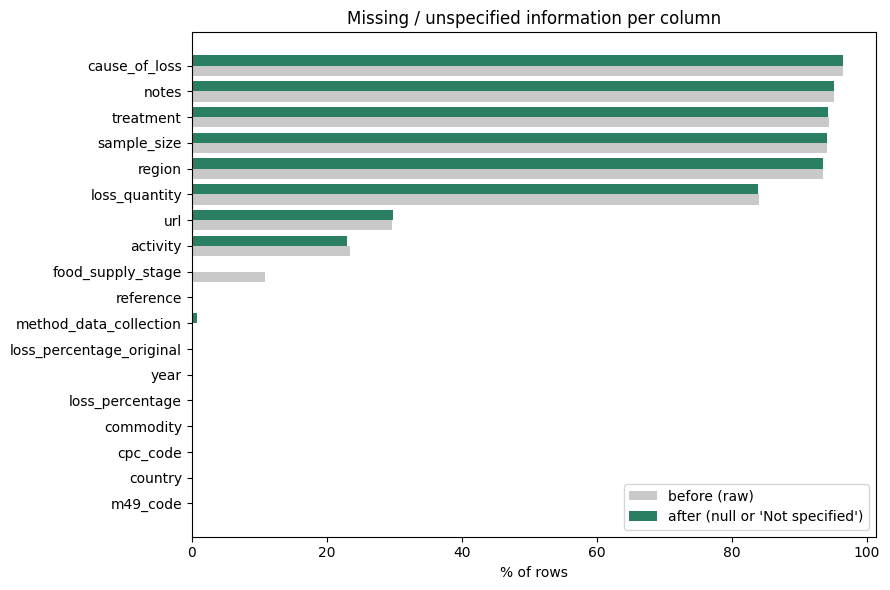

In [19]:
original_columns = [c for c in raw.columns]
before_missing = raw[original_columns].isna().mean().mul(100)

# information still present somewhere in the cleaned table, per ORIGINAL column
after_view = clean.rename(columns={"loss_quantity_raw": "loss_quantity"})[original_columns].copy()
after_view["sample_size"] = clean["sample_size"].astype("string").fillna(clean["sample_size_description"])
after_missing = (after_view.isna() | after_view.eq(NOT_SPECIFIED)).mean().mul(100)

compare = pd.DataFrame({"before_%": before_missing.round(2), "after_%": after_missing.round(2)})
compare["change_pp"] = (compare["after_%"] - compare["before_%"]).round(2)
display(compare.sort_values("before_%", ascending=False))

fig, ax = plt.subplots(figsize=(9, 6))
order = compare.sort_values("before_%").index
y = np.arange(len(order))
ax.barh(y - 0.2, compare.loc[order, "before_%"], height=0.4, label="before (raw)", color="#c9c9c9")
ax.barh(y + 0.2, compare.loc[order, "after_%"], height=0.4, label="after (null or 'Not specified')", color="#2a7f62")
ax.set_yticks(y); ax.set_yticklabels(order); ax.set_xlabel("% of rows")
ax.set_title("Missing / unspecified information per column"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 17. Validation — assert that the cleaned data meets every rule

Each check below is executed and shown as PASS / FAIL; the notebook stops if any rule is violated.

In [20]:
checks = {
    "no exact duplicate rows":                         not clean.drop(columns="source_row_id").duplicated().any(),
    "no leading/trailing/double spaces in text":       not any(clean[c].dropna().astype(str).str.contains(r"^\s|\s$|\s{2,}").any()
                                                           for c in clean.select_dtypes(include=["string", "object"]).columns),
    "m49_code is a 3-digit string":                    clean["m49_code"].str.fullmatch(r"\d{3}").all(),
    "one m49_code <-> one country":                    (clean.groupby("m49_code")["country"].nunique() == 1).all()
                                                       and (clean.groupby("country")["m49_code"].nunique() == 1).all(),
    "no country alias names remain":                   not clean["country"].isin(["China,Taiwan", "Palestine", "Netherlands", "Turkey",
                                                           "United Kingdom", "The former Yugoslav Republic of Macedonia"]).any(),
    "one commodity label per cpc_code (and back)":     (clean.groupby("cpc_code")["commodity"].nunique() == 1).all()
                                                       and (clean.groupby("commodity")["cpc_code"].nunique() == 1).all(),
    "no HTML tags in commodity":                       not clean["commodity"].str.contains("<|>").any(),
    "cpc_code keeps leading zeros (text dtype)":       clean["cpc_code"].str.startswith("0").any() and clean["cpc_code"].dtype.name in ("string", "str", "object"),
    "year is Int64 within accepted window":            str(clean["year"].dtype) == "Int64" and clean["year"].between(MIN_PLAUSIBLE_YEAR, MAX_PLAUSIBLE_YEAR).all(),
    "loss_percentage in [0, 100], no nulls":           clean["loss_percentage"].between(0, 100).all(),
    "loss_quantity_tonnes >= 0":                       (clean["loss_quantity_tonnes"].dropna() >= 0).all(),
    "quantity basis present wherever raw text exists": clean.loc[clean["loss_quantity_raw"].notna(), "loss_quantity_basis"].notna().all(),
    "sample_size is a positive integer or null":       (clean["sample_size"].dropna() > 0).all(),
    "activity / stage / method have no nulls":         clean[["activity", "food_supply_stage", "method_data_collection"]].notna().all().all(),
    "aggregates flagged consistently":                 clean["is_aggregate"].eq(clean["geo_level"].ne("Country/Area")).all(),
    "is_subnational matches region":                   clean["is_subnational"].eq(clean["region"].notna()).all(),
    "every url cell holds a valid link":               clean["url"].dropna().str.contains(r"https?://").all(),
}
report = pd.DataFrame({"check": list(checks), "result": ["PASS" if bool(v) else "FAIL" for v in checks.values()]})
display(report)
assert (report["result"] == "PASS").all(), "At least one validation rule failed"
print("All validation rules passed.")

,check,result
0,no exact duplicate rows,PASS
1,no leading/trailing/double spaces in text,PASS
2,m49_code is a 3-digit string,PASS
3,one m49_code <-> one country,PASS
4,no country alias names remain,PASS
5,one commodity label per cpc_code (and back),PASS
6,no HTML tags in commodity,PASS
7,cpc_code keeps leading zeros (text dtype),PASS
8,year is Int64 within accepted window,PASS
9,"loss_percentage in [0, 100], no nulls",PASS


All validation rules passed.


### Optional — re-validate country/code pairs against the official UN M49 table

Step 1 validated `(country, m49_code)` pairs against the UN M49 overview. This cell repeats that check on the **cleaned** data. It needs internet access; if the UN page cannot be reached the cell reports that and the notebook continues (the offline checks above do not depend on it). `Taiwan, Province of China` is not listed by the UN overview, so it is expected to appear under *REVIEW*.

In [21]:
UN_M49_URL = "https://unstats.un.org/unsd/methodology/m49/overview/"
try:
    import requests
    from io import StringIO

    response = requests.get(UN_M49_URL, timeout=30, headers={"User-Agent": "Mozilla/5.0"})
    response.raise_for_status()
    un_table = next(t for t in pd.read_html(StringIO(response.text))
                    if {"Country or Area", "M49 Code"}.issubset(t.columns))

    pairs = [(un_table["Country or Area"], un_table["M49 Code"])]
    for name_col, code_col in [("Global Name", "Global Code"), ("Region Name", "Region Code"),
                               ("Sub-region Name", "Sub-region Code"),
                               ("Intermediate Region Name", "Intermediate Region Code")]:
        if name_col in un_table.columns and code_col in un_table.columns:
            pairs.append((un_table[name_col], un_table[code_col]))

    official = set()
    for names, codes in pairs:
        for name, code in zip(names, codes):
            if pd.notna(name) and pd.notna(code):
                official.add((str(int(float(code))).zfill(3), str(name).strip().casefold()))

    unique_pairs = clean[["m49_code", "country"]].drop_duplicates().copy()
    unique_pairs["status"] = [
        "OK" if (code, name.strip().casefold()) in official else "REVIEW"
        for code, name in zip(unique_pairs["m49_code"], unique_pairs["country"])
    ]
    print(unique_pairs["status"].value_counts().to_string())
    display(unique_pairs[unique_pairs["status"] == "REVIEW"].reset_index(drop=True))
except Exception as exc:
    print(f"UN M49 reference not reachable here ({type(exc).__name__}); online validation skipped.")

UN M49 reference not reachable here (ConnectionError); online validation skipped.


## 18. What the cleaning changed — overview

The tables below summarise the whole pipeline: the row/null count after every step, every rule applied, and a high-level before/after comparison.

In [22]:
print("Pipeline checkpoints (state of the data after each step):")
display(pd.DataFrame(checkpoints))

log_df = pd.DataFrame(change_log)
print("\nCleaning actions (rule-level log):")
display(log_df)

overview = pd.DataFrame([
    ("Rows",                              len(raw),                          len(clean)),
    ("Columns",                           raw.shape[1],                      clean.shape[1]),
    ("Exact duplicate rows",              int(raw.duplicated().sum()),       int(clean.drop(columns="source_row_id").duplicated().sum())),
    ("Distinct country/area names",       raw["country"].nunique(),          clean["country"].nunique()),
    ("Distinct commodity labels",         raw["commodity"].nunique(),        clean["commodity"].nunique()),
    ("Distinct region labels",            raw["region"].nunique(),           clean["region"].nunique()),
    ("Rows with a known food_supply_stage", int(raw["food_supply_stage"].notna().sum()), int(clean["food_supply_stage"].ne(NOT_SPECIFIED).sum())),
    ("Rows with a known activity",        int(raw["activity"].notna().sum()), int(clean["activity"].ne(NOT_SPECIFIED).sum())),
    ("Rows with a numeric loss quantity (raw: plain numbers; cleaned: tonnes)",
     int(pd.to_numeric(raw["loss_quantity"], errors="coerce").notna().sum()), int(clean["loss_quantity_tonnes"].notna().sum())),
    ("Rows labelled as geographic aggregates", 0,                            int(clean["is_aggregate"].sum())),
], columns=["metric", "raw", "cleaned"])
print("\nBefore vs after:")
display(overview)

Pipeline checkpoints (state of the data after each step):


,step,rows,columns,null_cells_original_columns
0,0. raw load,31465,19,195635
1,1. text normalisation,31465,19,195641
2,2. exact duplicates,31285,19,194413
3,3. m49_code + country,31285,21,194413
4,4. region,31285,22,194424
5,5. cpc_code + commodity,31285,22,194424
6,6. year,31285,23,194424
7,7. loss_percentage,31285,24,194424
8,8. loss_quantity,31285,27,194424
9,9. activity / stage / treatment / cause,31285,28,183827



Cleaning actions (rule-level log):


,step,column,rule,rows_affected
0,1. text normalisation,region,NFKC + trim/collapse whitespace + blank/placeholder -> null,84
1,1. text normalisation,loss_percentage_original,NFKC + trim/collapse whitespace + blank/placeholder -> null,6
2,1. text normalisation,loss_quantity,NFKC + trim/collapse whitespace + blank/placeholder -> null,8
3,1. text normalisation,treatment,NFKC + trim/collapse whitespace + blank/placeholder -> null,65
4,1. text normalisation,cause_of_loss,NFKC + trim/collapse whitespace + blank/placeholder -> null,129
5,1. text normalisation,sample_size,NFKC + trim/collapse whitespace + blank/placeholder -> null,89
6,1. text normalisation,reference,NFKC + trim/collapse whitespace + blank/placeholder -> null,147
7,1. text normalisation,notes,NFKC + trim/collapse whitespace + blank/placeholder -> null,262
8,2. exact duplicates,(all),"dropped exact duplicate rows, kept first occurrence",180
9,3. m49_code + country,m49_code,text -> zero-padded 3-character code,31285



Before vs after:


,metric,raw,cleaned
0,Rows,31465,31280
1,Columns,18,30
2,Exact duplicate rows,180,0
3,Distinct country/area names,159,157
4,Distinct commodity labels,213,196
5,Distinct region labels,378,363
6,Rows with a known food_supply_stage,28074,31233
7,Rows with a known activity,24095,24076
8,Rows with a numeric loss quantity (raw: plain numbers; cleaned: to...,4359,4931
9,Rows labelled as geographic aggregates,0,107


### Quick sanity view — does the cleaned data now behave sensibly?

Median loss % by supply-chain stage for **country-level rows only** (`~is_aggregate`), with the specific `Not specified` and `Whole supply chain` groups kept separate.

,records,median_loss_pct
food_supply_stage,,
Transport,2088,1.00
Stacking,1,2.10
Market,101,2.30
Packing,48,2.35
Farm,13415,2.50
Storage,3203,2.65
Processing,399,3.00
Harvest,4151,4.40
Trader,104,4.47


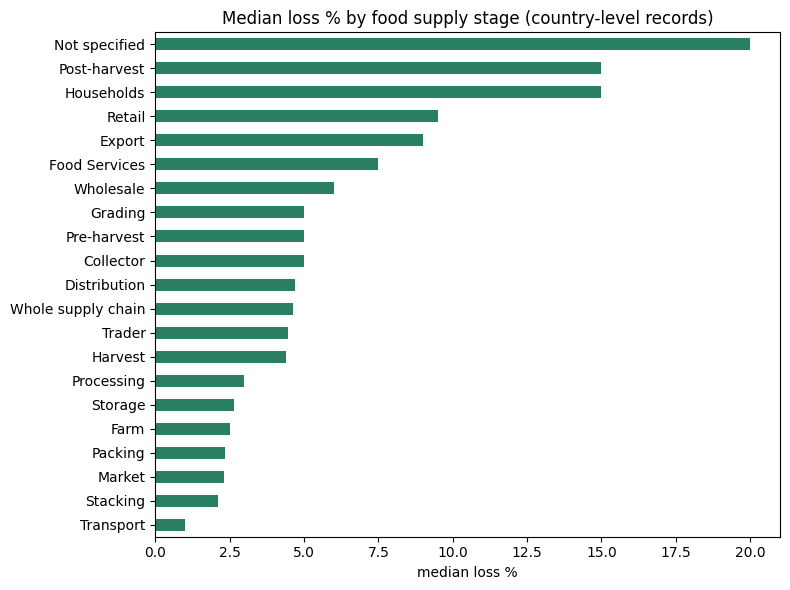

In [23]:
country_level = clean[~clean["is_aggregate"]]
by_stage = (country_level.groupby("food_supply_stage")["loss_percentage"]
            .agg(records="size", median_loss_pct="median").sort_values("median_loss_pct"))
display(by_stage.round(2))

fig, ax = plt.subplots(figsize=(8, 6))
by_stage["median_loss_pct"].plot.barh(ax=ax, color="#2a7f62")
ax.set_xlabel("median loss %"); ax.set_ylabel("")
ax.set_title("Median loss % by food supply stage (country-level records)")
plt.tight_layout(); plt.show()

## 19. Export the cleaned data and audit files

In [24]:
clean_path = OUTPUT_DIR / "world_food_loss_cleaned.csv"
clean.to_csv(clean_path, index=False, encoding="utf-8-sig")

pd.DataFrame(change_log).to_csv(OUTPUT_DIR / "cleaning_change_log.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(value_change_log).to_csv(OUTPUT_DIR / "cleaning_value_changes.csv", index=False, encoding="utf-8-sig")
flag_summary.to_csv(OUTPUT_DIR / "data_quality_flags_summary.csv", index=False, encoding="utf-8-sig")

# round-trip test: reload the file and confirm nothing was damaged on the way to disk
reloaded = pd.read_csv(clean_path, dtype={"m49_code": str, "cpc_code": str})
assert len(reloaded) == len(clean) and reloaded["cpc_code"].str.startswith("0").any()
assert reloaded["m49_code"].str.fullmatch(r"\d{3}").all()

files = pd.DataFrame([(p.name, f"{p.stat().st_size / 1024:,.0f} KB") for p in sorted(OUTPUT_DIR.glob("*.csv"))],
                     columns=["file", "size"])
display(files)
print(f"Saved {len(clean):,} cleaned rows x {clean.shape[1]} columns to {OUTPUT_DIR}/")

,file,size
0,cleaning_change_log.csv,3 KB
1,cleaning_value_changes.csv,199 KB
2,data_quality_flags_summary.csv,0 KB
3,world_food_loss_cleaned.csv,"8,823 KB"


Saved 31,280 cleaned rows x 30 columns to cleaned_data/


## Notes for the next step

* **Read the cleaned CSV with `dtype={"m49_code": str, "cpc_code": str}`** — otherwise pandas turns `004` into `4` and `0111` into `111`.
* **Country-level analysis:** filter `~is_aggregate`. Regional/world rows are FAO estimates for whole regions; summing them with countries double-counts.
* **Quantities:** use `loss_quantity_tonnes` and look at `loss_quantity_basis` — `assumed_tonnes_no_unit` rows rely on the FAO tonnes convention; `not_convertible` rows have a rate or count instead of a total.
* **Ranges:** `loss_pct_is_range` / `loss_quantity_is_range` mark values that are midpoints.
* **Review flags:** `dq_flags` lists suspicious-but-kept rows; filter or inspect them rather than deleting by default.
* **`region`** stays null for national records on purpose — use `is_subnational`.
* `Not specified` appears in `activity`, `food_supply_stage` and `method_data_collection`; treat it as an *unknown* category in grouped analysis.